# Failure experiments (phone set)

One small inference-only experiment per selected failure photo. Photos, hypotheses, variants and refutation criteria are in `configs/failure_experiments.yaml` and were written before any variant was run.

- Every variant is predicted with the evaluation code of the trained checkpoint. Masks are mapped back to the original photo before matching (score >= 0.25, IoU >= 0.5).
- The unchanged photo must reproduce the exported predictions (check below).
- `top class` in brackets is the highest-scoring prediction of any class with IoU >= 0.5 on the object, also below the score threshold.
- One photo per experiment: a result supports or contradicts an explanation for that photo. It does not measure how often the explanation holds.
- Run time about 10 minutes (three models) on the RTX 4050, GPU needed. `SMOKE = True` runs the crop experiment with YOLO only (about 1 minute) and writes to `runs/smoke/`.

## Parameters

In [1]:
MODELS = ["yolo", "maskrcnn", "m2f"]
SIZE = 640
OUT_DIR = "results/failures"
SMOKE = False

In [2]:
%config InlineBackend.figure_formats = ['jpeg']
import logging

import matplotlib.pyplot as plt
import pandas as pd

from iiss.analysis import failure_experiments as fe
from iiss.analysis import failures as fa
from iiss.utils.paths import repo_root

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.max_columns", 30, "display.max_rows", 100, "display.width", 200)
pd.set_option("display.max_colwidth", 90, "display.float_format", "{:.3f}".format)

In [3]:
config = fe.load_experiments()
specs = config["experiments"]
if SMOKE:
    MODELS, OUT_DIR = ["yolo"], "runs/smoke/failures"
    specs = {k: v for k, v in specs.items() if k in ("crop", "mask_grid")}
runs = fe.default_run_ids({"models": MODELS, "input_size": SIZE})
split, limits = fa.load_gt_set("phone"), fa.default_limits()
print(runs, limits, sep="\n")

['yolo_s640_seed42', 'maskrcnn_s640_seed42', 'm2f_s640_seed42']
Limits(score_threshold=0.25, match_iou=0.5, good_iou=0.75, partial_iou=0.1)


## Run all variants

In [4]:
outcomes = fe.run_experiments(specs, split, runs, limits)
table = fe.result_table(outcomes)
print(len(outcomes), "predictions,", len(table), "target rows")

c:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 554/554 [00:00<00:00, 1730.58it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+--------------------------------------------------------------------------------------

69 predictions, 105 target rows


Baseline check: the unchanged photo compared with the exported predictions. `same_tags` must be True in every row.

In [5]:
baseline = fe.check_baseline(outcomes, split, limits)
assert baseline["same_tags"].all()
baseline

,experiment,run_id,same_tags,n_shown,n_shown_exported,max_score_diff
0,low_light,yolo_s640_seed42,True,1,1,0.000
1,zoom_out,yolo_s640_seed42,True,6,6,0.000
2,crop,yolo_s640_seed42,True,1,1,0.000
3,wall_edge,yolo_s640_seed42,True,2,2,0.000
4,low_light,maskrcnn_s640_seed42,True,2,2,0.000
5,zoom_out,maskrcnn_s640_seed42,True,14,14,0.000
6,crop,maskrcnn_s640_seed42,True,2,2,0.000
7,wall_edge,maskrcnn_s640_seed42,True,5,5,0.000
8,low_light,m2f_s640_seed42,True,1,1,0.000
9,zoom_out,m2f_s640_seed42,True,6,6,0.000


In [6]:
def fig_path(name):
    return repo_root() / OUT_DIR / f"exp_{name}.jpg"


def show(name):
    s = specs[name]
    print(s["photo"], "|", s["failure"], "| focus", s["focus"])
    print("Hypothesis:", s["hypothesis"].strip(), "\nRefuted if:", s["refuted_if"])
    if name != "mask_grid":
        for run in runs:
            fe.plot_variants(
                outcomes, name, run, split.category_names, save_to=fig_path(f"{name}_{run}")
            )
            plt.show()

## 1. Low light

Gamma and CLAHE brighten the photo. The chair is the target.

IMG_20261124_172832.jpg | chair missed in low light (mean gray value 12.7 of 255) | focus yolo
Hypothesis: The contrast of the chair is too low for the convolutional features of YOLO, so no class score passes the threshold, although the shape is still present in the pixels. 
Refuted if: the chair is not matched in any brightened variant


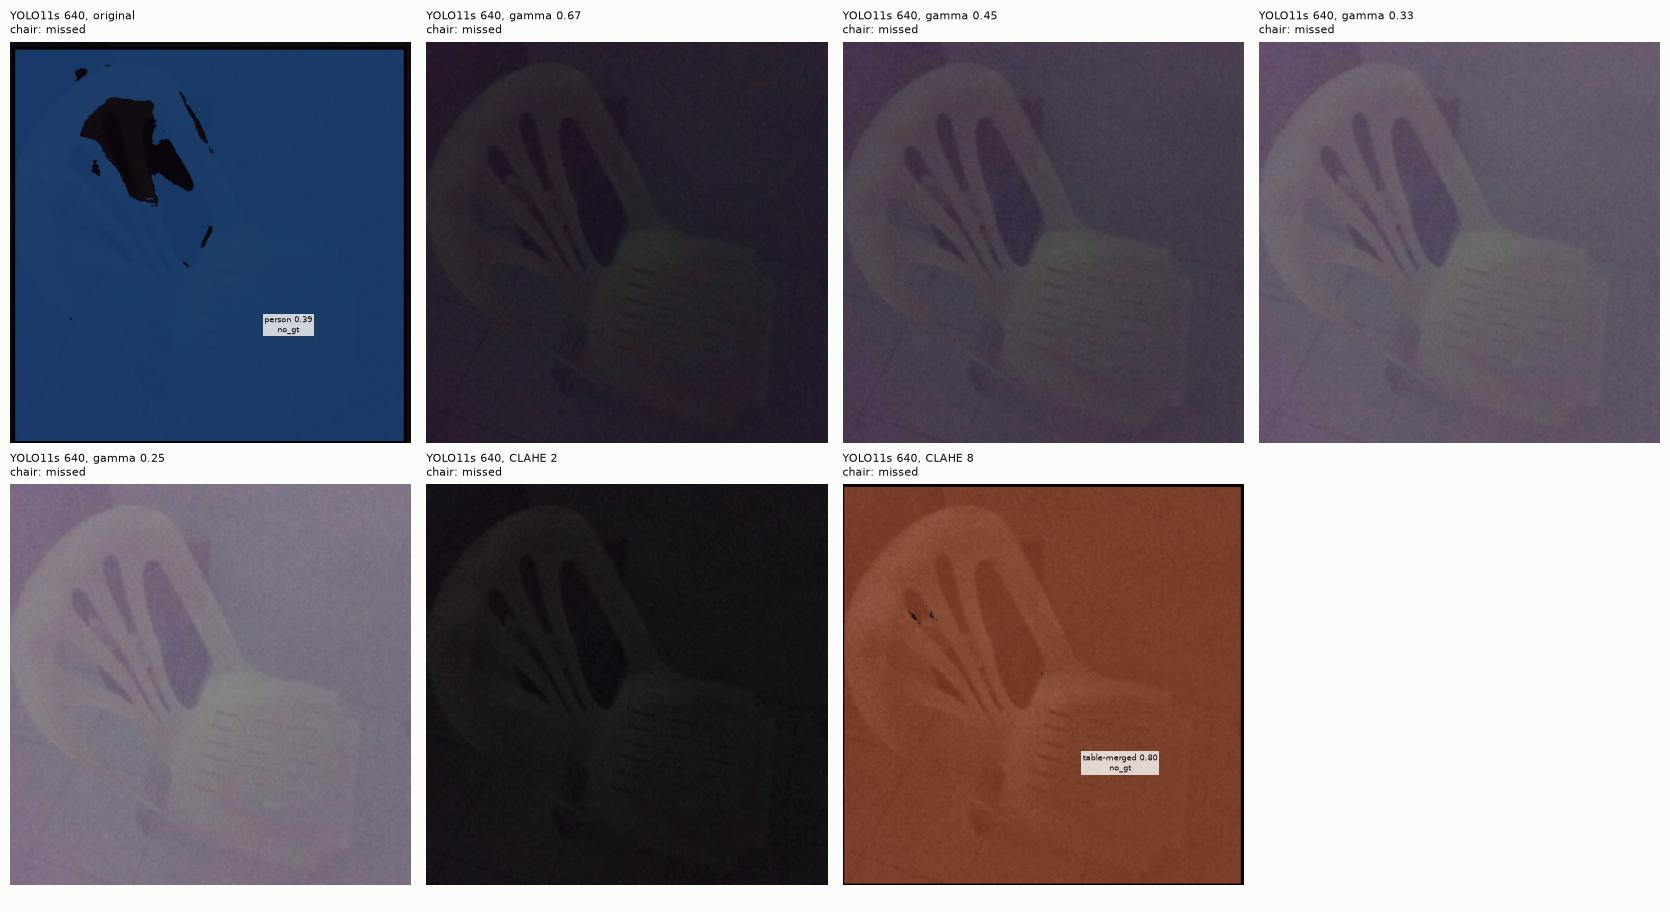

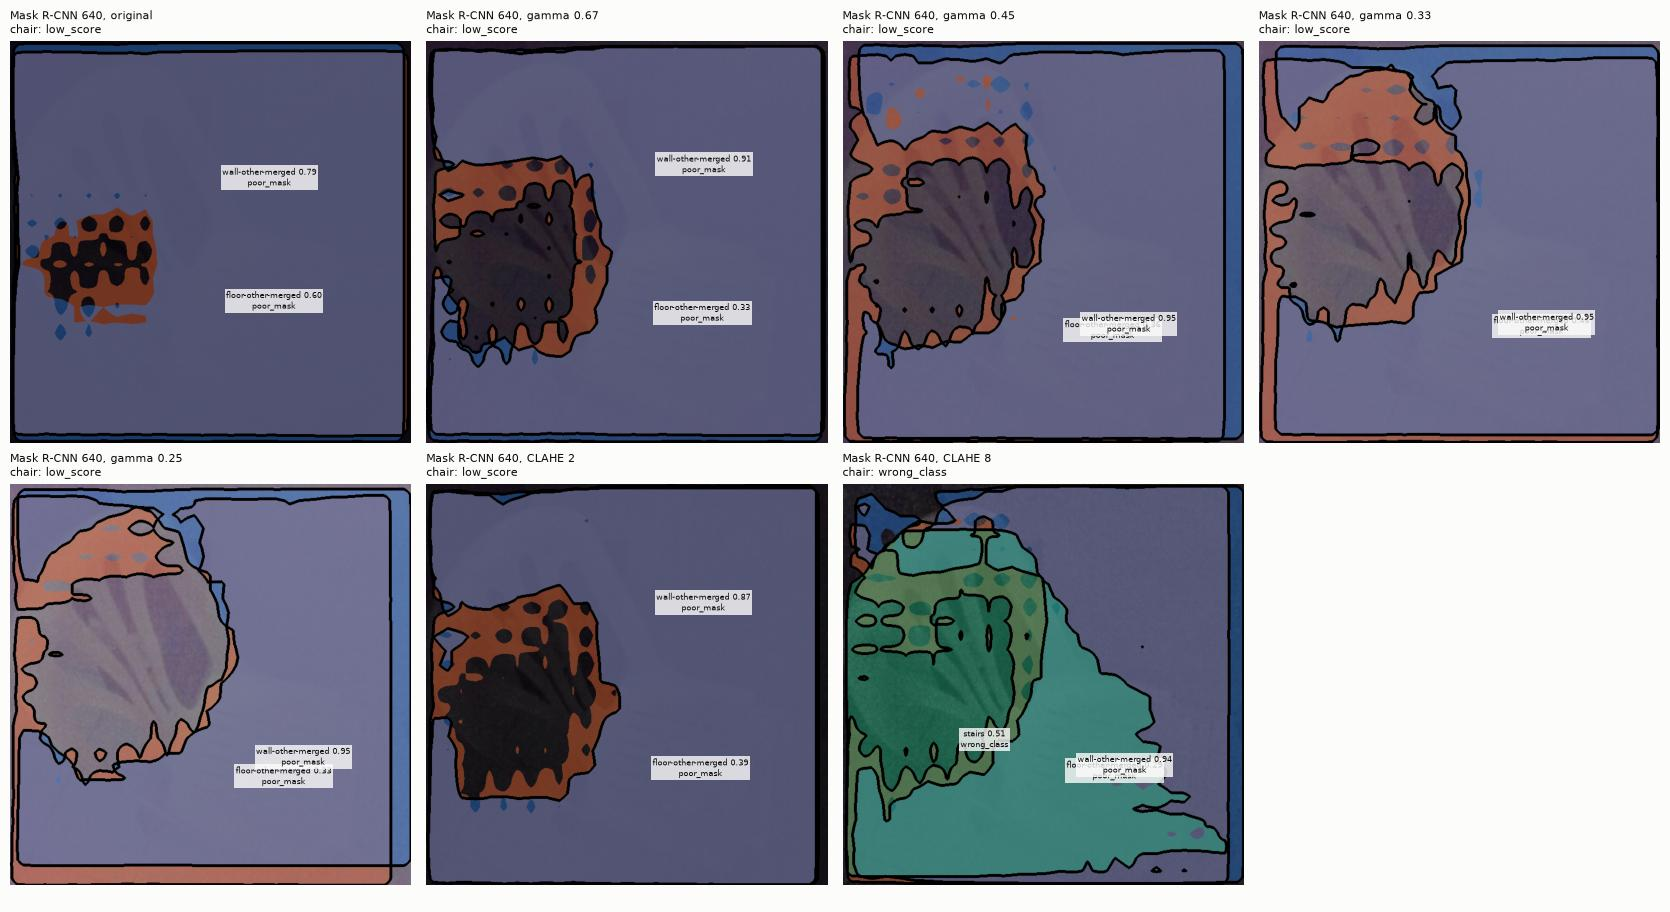

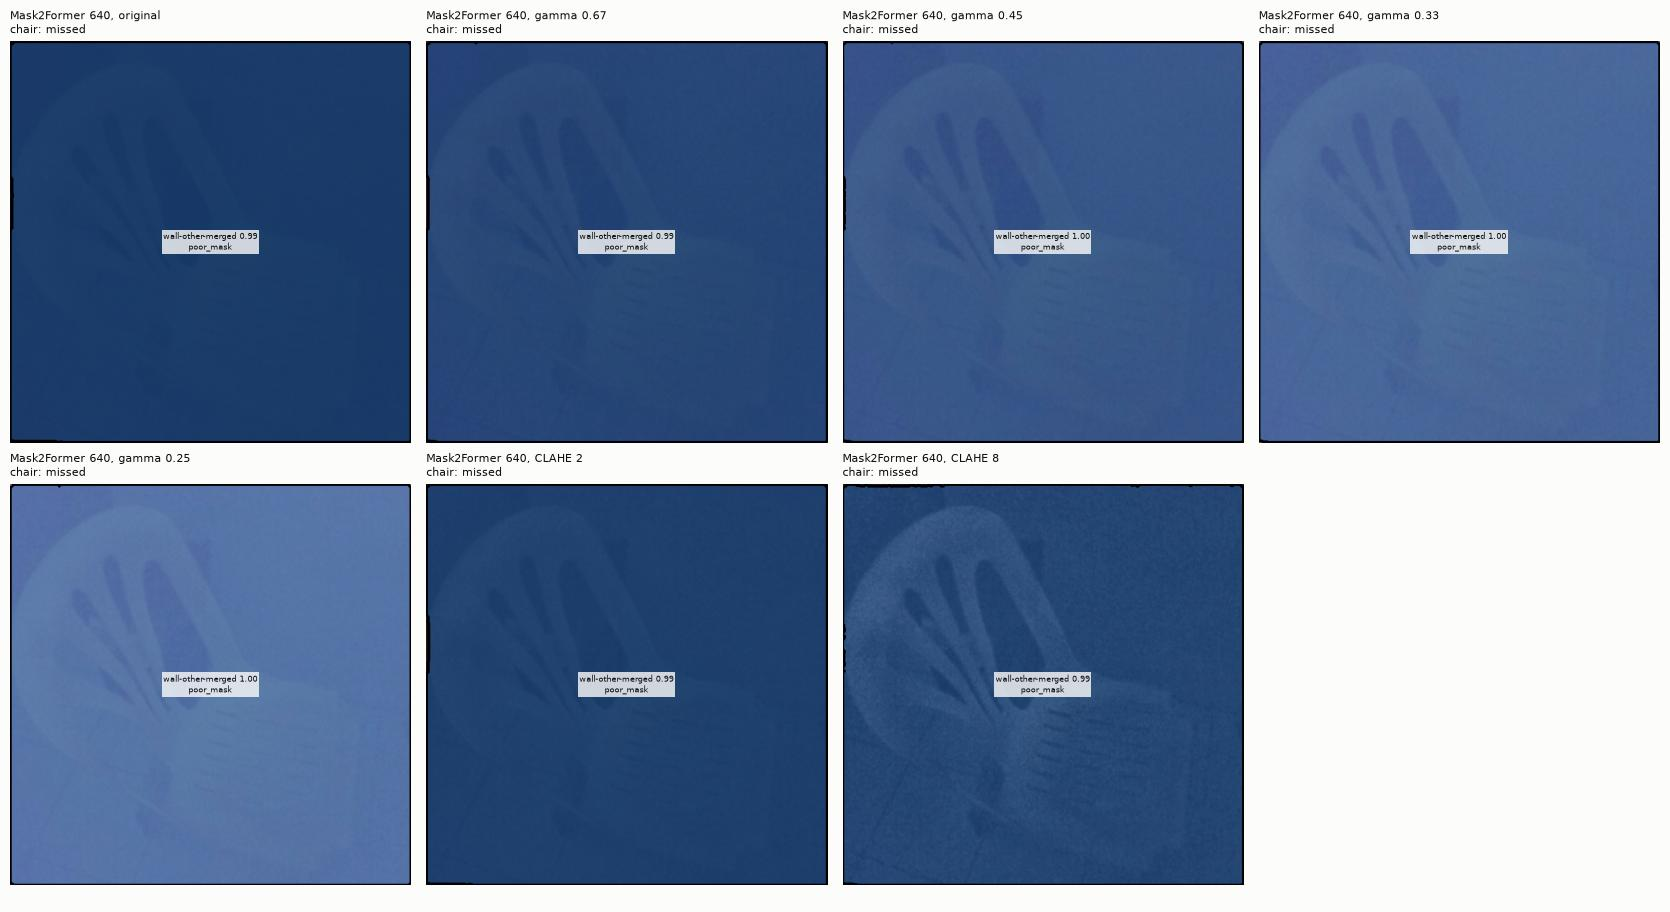

model                                       yolo                     maskrcnn                               m2f
gt_id name  variant                                                                                            
165   chair original           missed [pan 0.03]  low_score [rug-merged 0.04]  missed [floor-other-merged 0.00]
            gamma 0.67         missed [pan 0.03]      low_score [stairs 0.05]  missed [floor-other-merged 0.00]
            gamma 0.45         missed [pan 0.00]      low_score [stairs 0.05]   missed [wall-other-merged 0.00]
            gamma 0.33                    missed         low_score [pan 0.06]   missed [wall-other-merged 0.00]
            gamma 0.25  missed [rug-merged 0.00]         low_score [pan 0.10]   missed [wall-other-merged 0.00]
            CLAHE 2            missed [pan 0.13]      low_score [stairs 0.11]  missed [floor-other-merged 0.00]
            CLAHE 8            missed [pan 0.00]    wrong_class [stairs 0.51]  missed [floor-other-merged 0.00]

In [7]:
if "low_light" in specs:
    show("low_light")
    display(fe.overview(table, "low_light"))

## 2. Zoom out

The photo is shrunk on a gray canvas. The canvas itself is new image content and the models may predict walls on it.

IMG_20261124_171925.jpg | pillow predicted as wallet | focus maskrcnn
Hypothesis: The RoI classifier also relies on object scale. In train a pillow covers 3.2 % of the image (median box), a wallet 16.5 %, so a large box-shaped object is pushed towards wallet. 
Refuted if: the pillow is still predicted as wallet at every scale


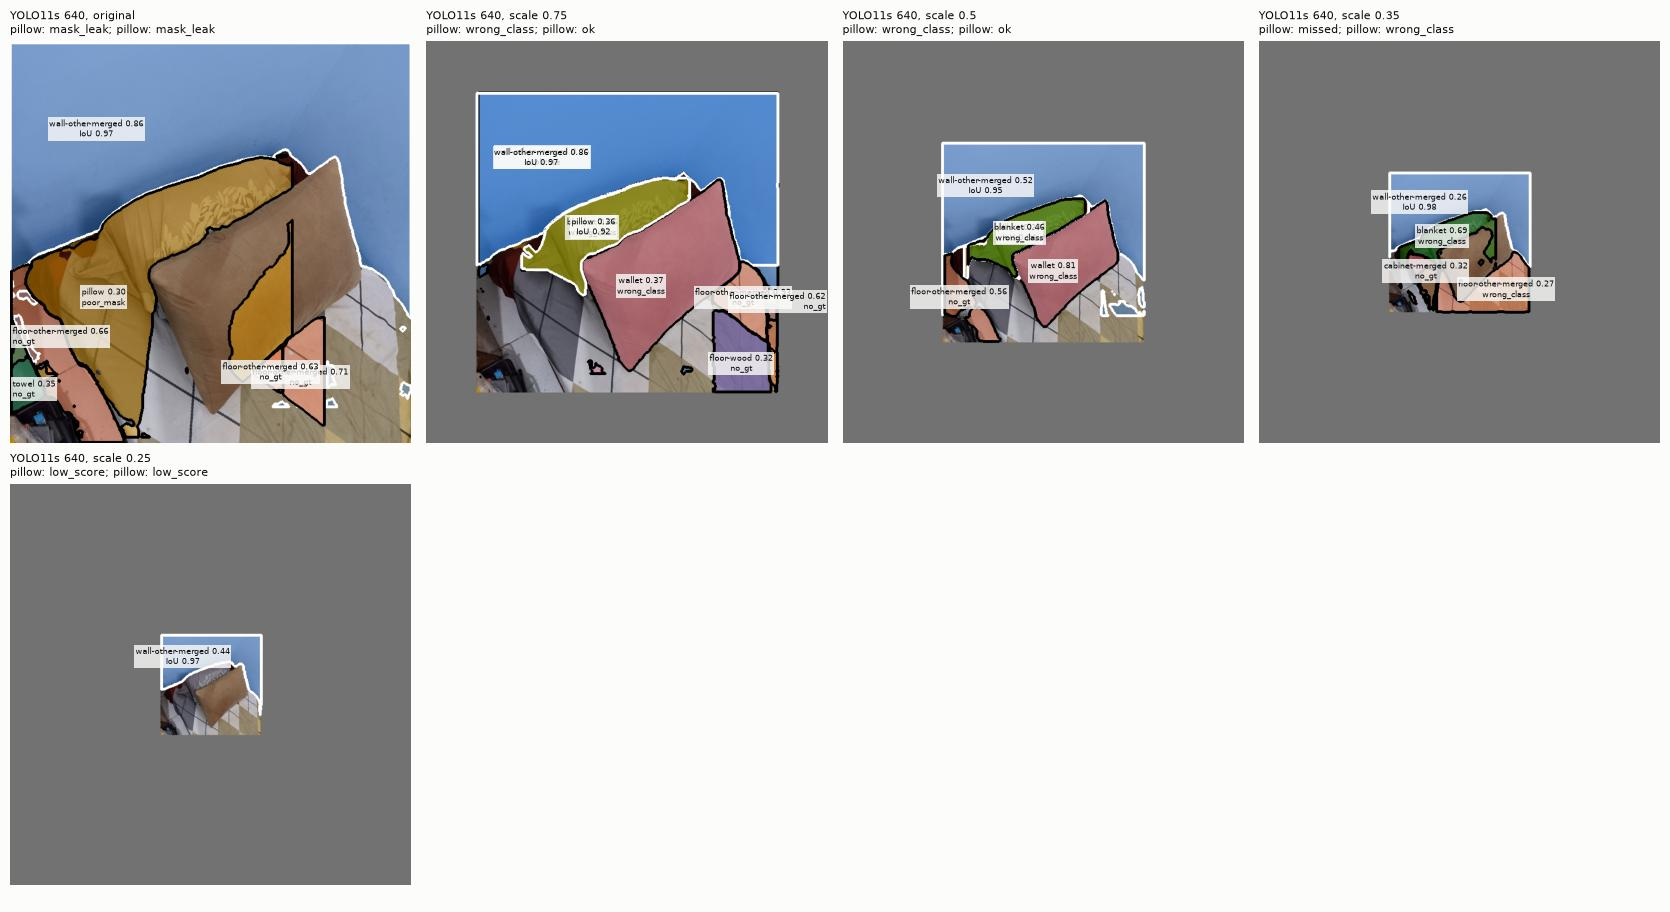

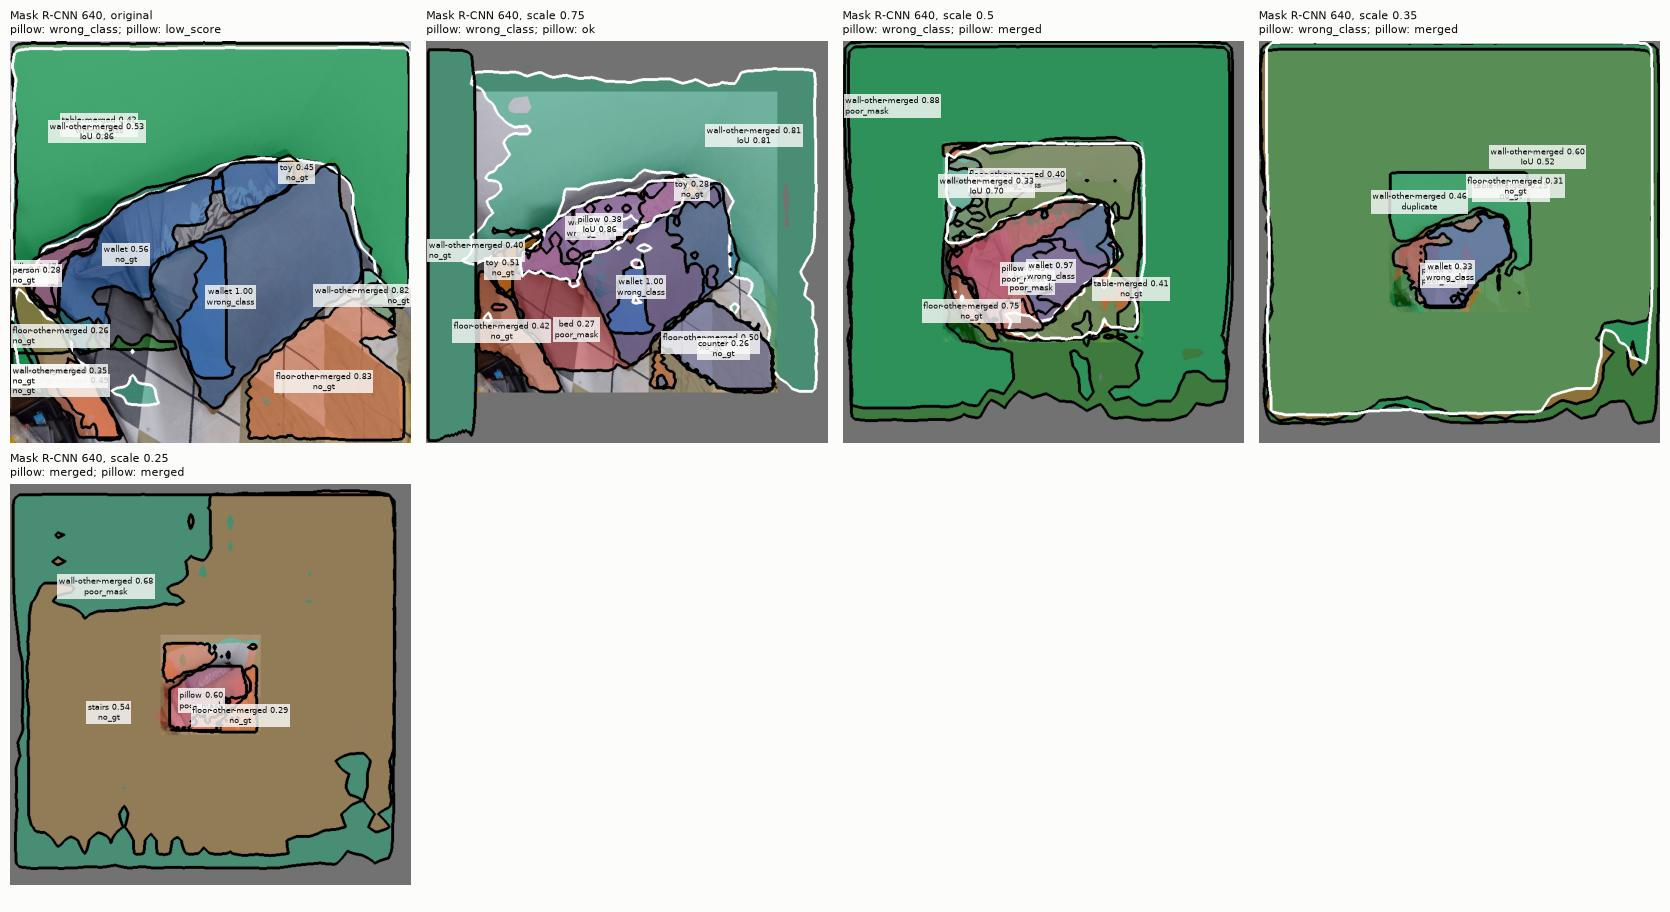

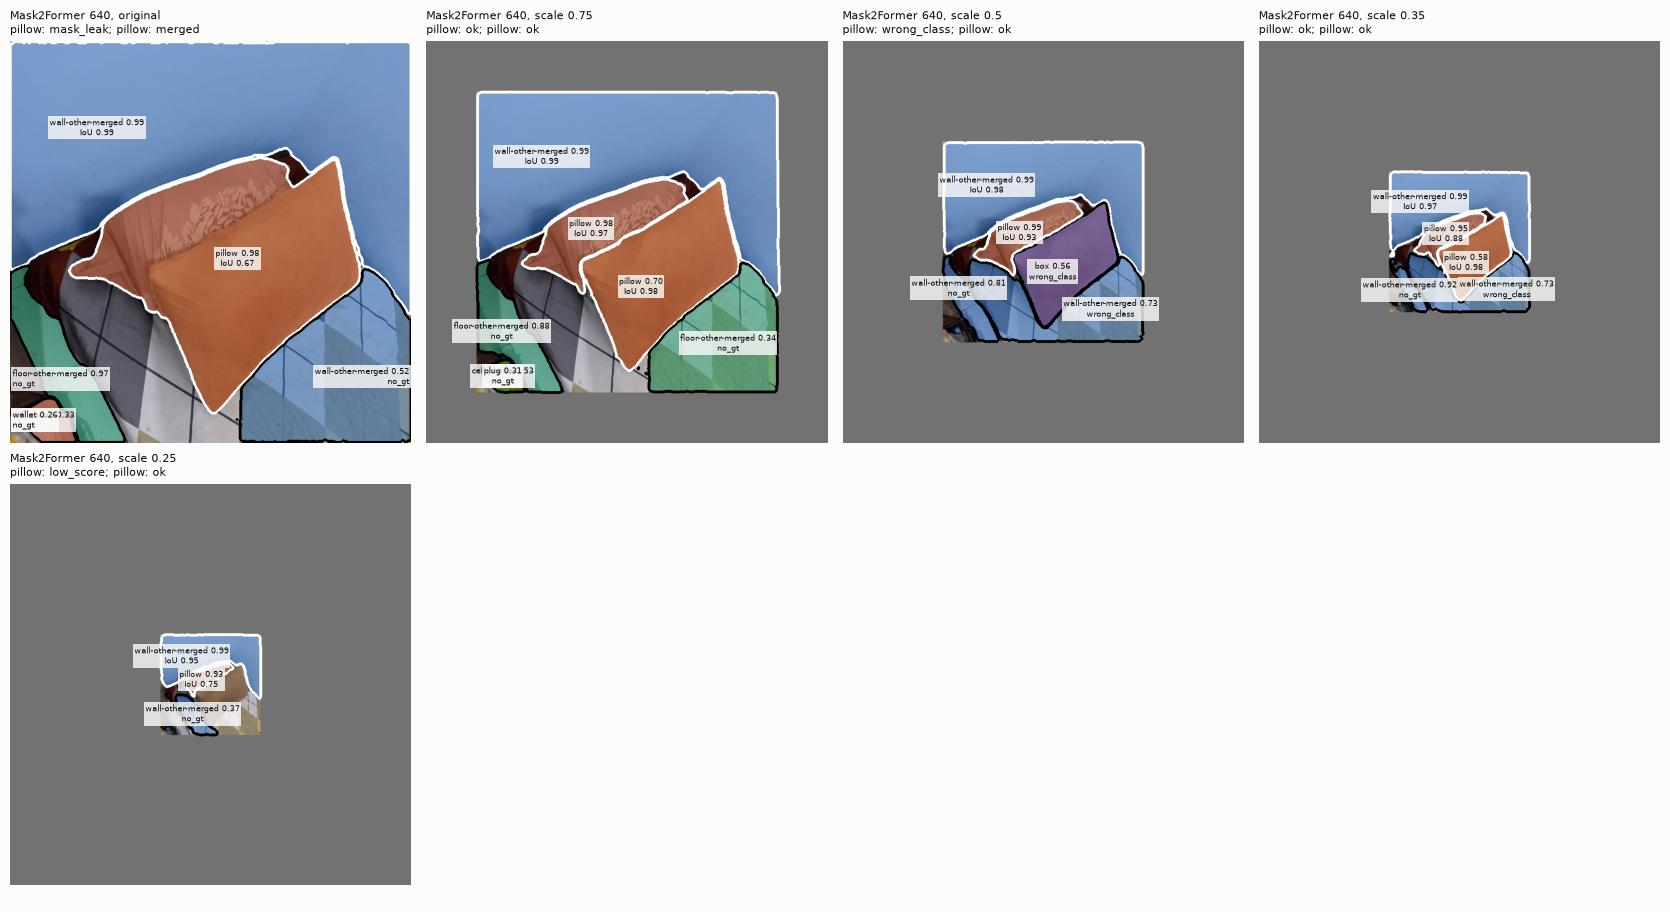

,,model,yolo,maskrcnn,m2f
gt_id,name,variant,,,
12,pillow,original,mask_leak [wallet 0.18],wrong_class [wallet 1.00],mask_leak IoU 0.67 [pillow 0.98]
11,pillow,original,mask_leak [pillow 0.02],low_score [pillow 0.06],merged [pillow 0.01]
12,pillow,scale 0.75,wrong_class [wallet 0.37],wrong_class [wallet 1.00],ok IoU 0.98 [pillow 0.70]
11,pillow,scale 0.75,ok IoU 0.92 [blanket 0.36],ok IoU 0.86 [wallet 0.84],ok IoU 0.97 [pillow 0.98]
12,pillow,scale 0.5,wrong_class [wallet 0.81],wrong_class [wallet 0.97],wrong_class [box 0.56]
11,pillow,scale 0.5,ok IoU 0.84 [blanket 0.46],merged,ok IoU 0.93 [pillow 0.99]
12,pillow,scale 0.35,missed [wallet 0.19],wrong_class [wallet 0.33],ok IoU 0.98 [pillow 0.58]
11,pillow,scale 0.35,wrong_class [blanket 0.69],merged [pillow 0.02],ok IoU 0.88 [pillow 0.95]
12,pillow,scale 0.25,low_score [wallet 0.15],merged [box 0.07],low_score [wallet 0.13]


In [8]:
if "zoom_out" in specs:
    show("zoom_out")
    display(fe.overview(table, "zoom_out"))

## 3. Mask grid

No model: the GT mask goes through a G x G grid and back, the best IoU a mask head of that resolution can reach. `iou_pred_box` uses the extent of the predicted mask.

IMG_20261124_172112.jpg | book mask incomplete with a ragged edge (IoU 0.62) | focus maskrcnn
Hypothesis: The fixed 28x28 mask grid is too coarse for an object that covers 40 % of the image. 
Refuted if: the GT mask sent through a 28x28 grid keeps IoU >= 0.95


,gt_id,name,target,grid,iou_gt_box,iou_pred_box,model_iou
0,21,book,True,14,0.981,0.975,0.625
1,21,book,True,28,0.989,0.985,0.625
2,21,book,True,56,0.993,0.988,0.625
3,21,book,True,112,0.993,0.989,0.625
4,22,table-merged,False,14,0.879,NaN,NaN
5,22,table-merged,False,28,0.943,NaN,NaN
6,22,table-merged,False,56,0.962,NaN,NaN
7,22,table-merged,False,112,0.972,NaN,NaN
8,23,table-merged,False,14,0.949,0.877,0.541
9,23,table-merged,False,28,0.970,0.910,0.541


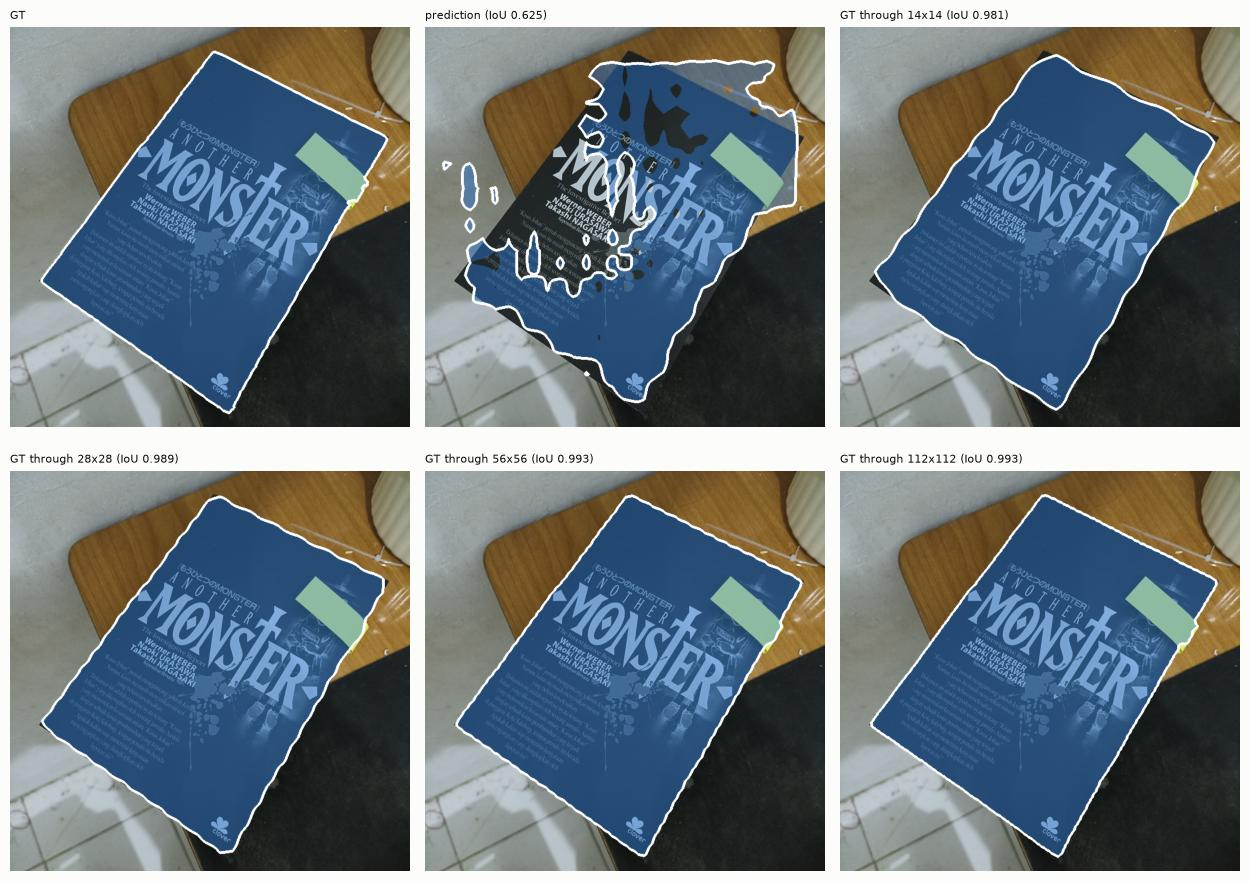

In [9]:
if "mask_grid" in specs:
    show("mask_grid")
    grid, masks = fe.grid_bound_table(specs["mask_grid"], split, f"maskrcnn_s{SIZE}_seed42", limits)
    fe.plot_grid_bound(specs["mask_grid"], split, grid, masks, fig_path("mask_grid"))
    display(grid)

## 4. Crop

The photo is cropped around the light, so the light gets larger.

IMG_20261124_172426.jpg | light missed by all three models (0.18 % of the image, about 27 px at S = 640) | focus maskrcnn
Hypothesis: The object is too small in the feature maps. 
Refuted if: the light is not matched in any crop, for the model in question


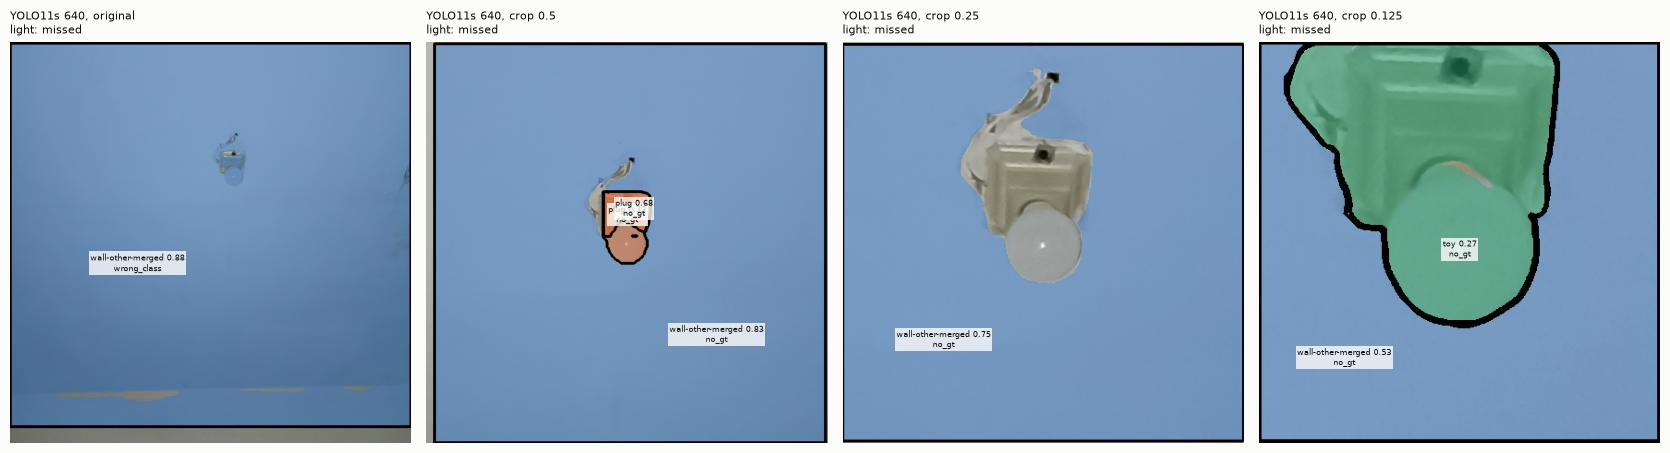

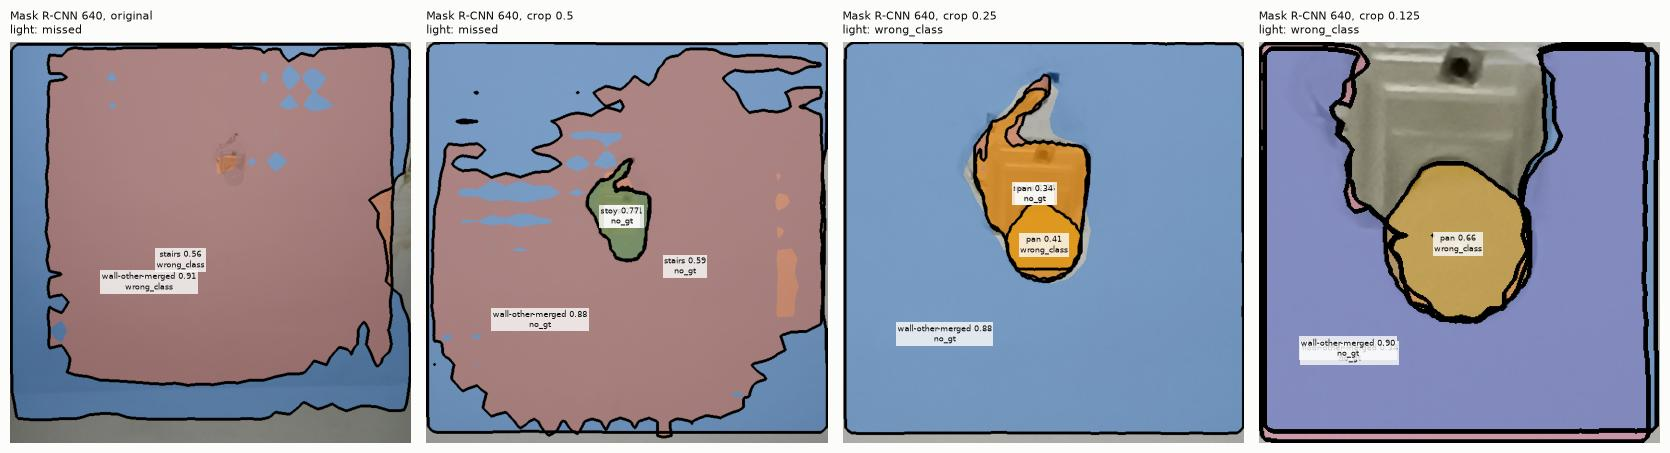

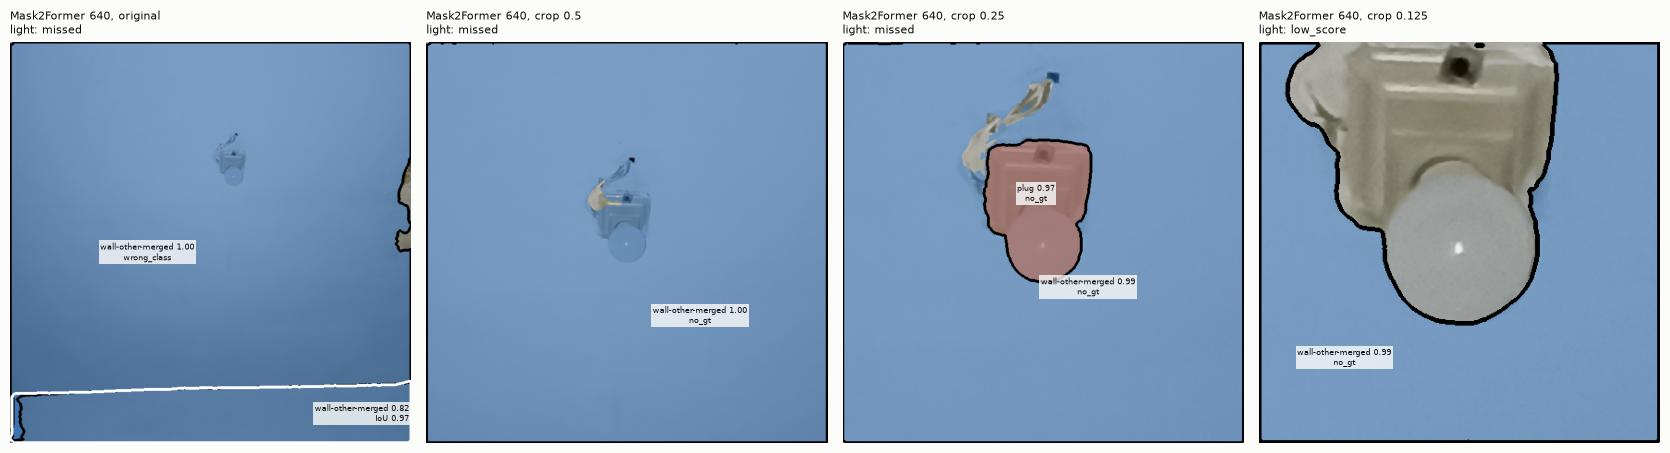

model                                  yolo                maskrcnn                   m2f
gt_id name  variant                                                                      
84    light original     missed [plug 0.02]                  missed                missed
            crop 0.5     missed [plug 0.15]                  missed                missed
            crop 0.25     missed [toy 0.02]  wrong_class [pan 0.41]                missed
            crop 0.125  missed [paper 0.15]  wrong_class [pan 0.66]  low_score [pan 0.00]

In [10]:
if "crop" in specs:
    show("crop")
    display(fe.overview(table, "crop"))

## 5. Wall edge

CLAHE, a black line on the GT boundary, or a darker second wall.

IMG_20261124_172438.jpg | two walls predicted as one instance | focus m2f
Hypothesis: The corner between the walls has almost no visible edge, so one query covers both walls. 
Refuted if: the walls stay merged although a clear edge is added


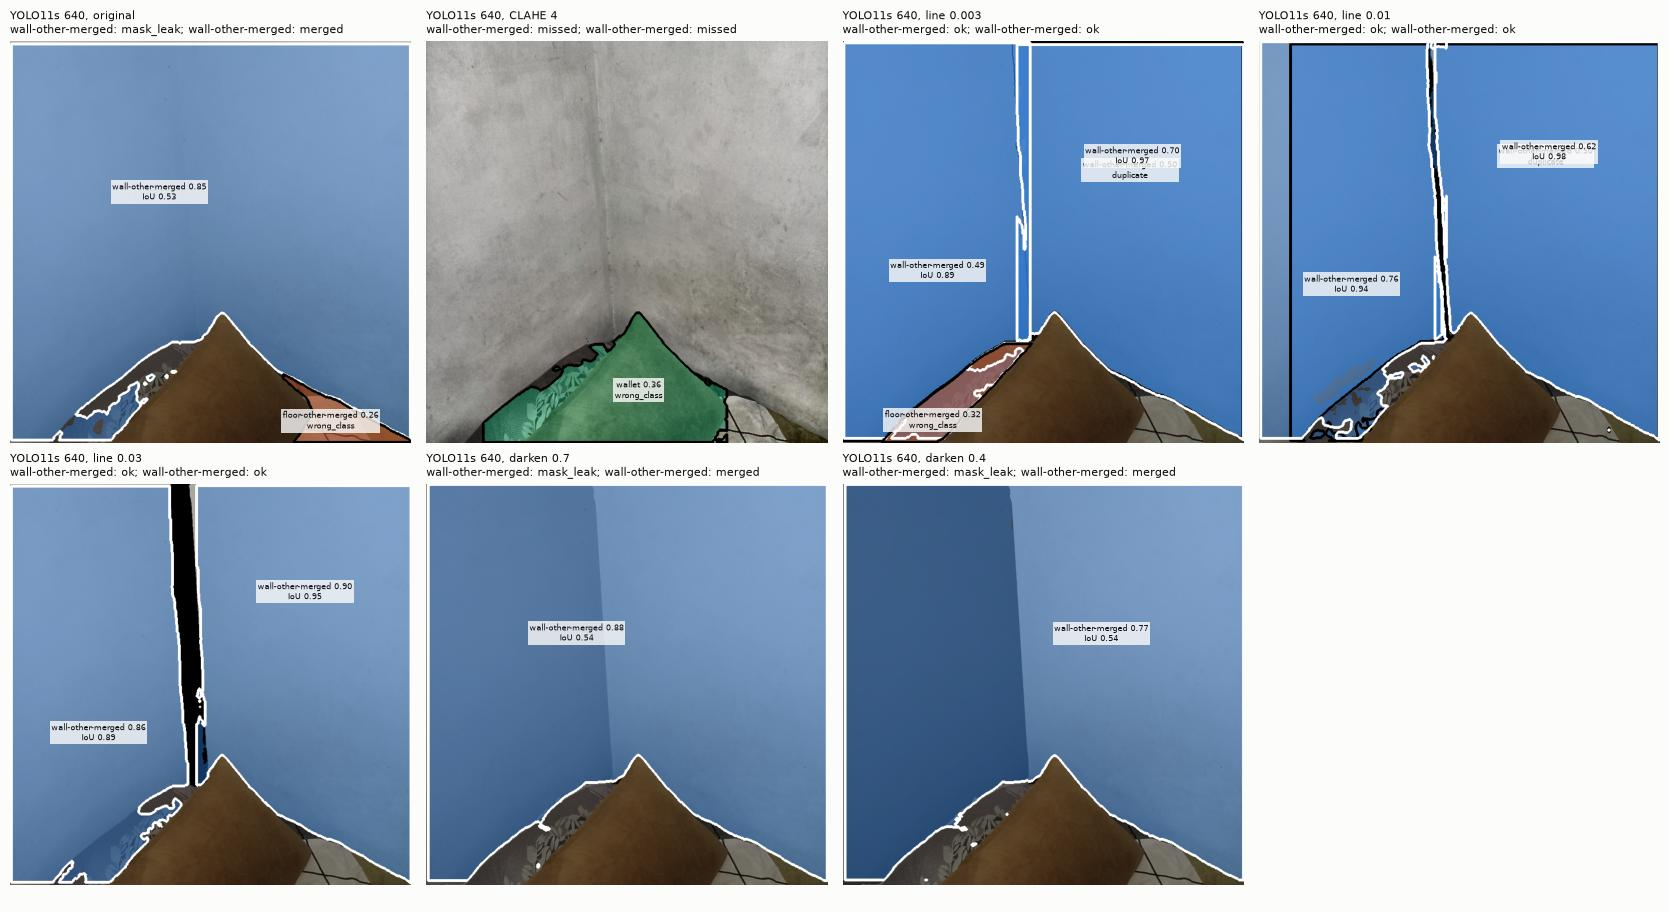

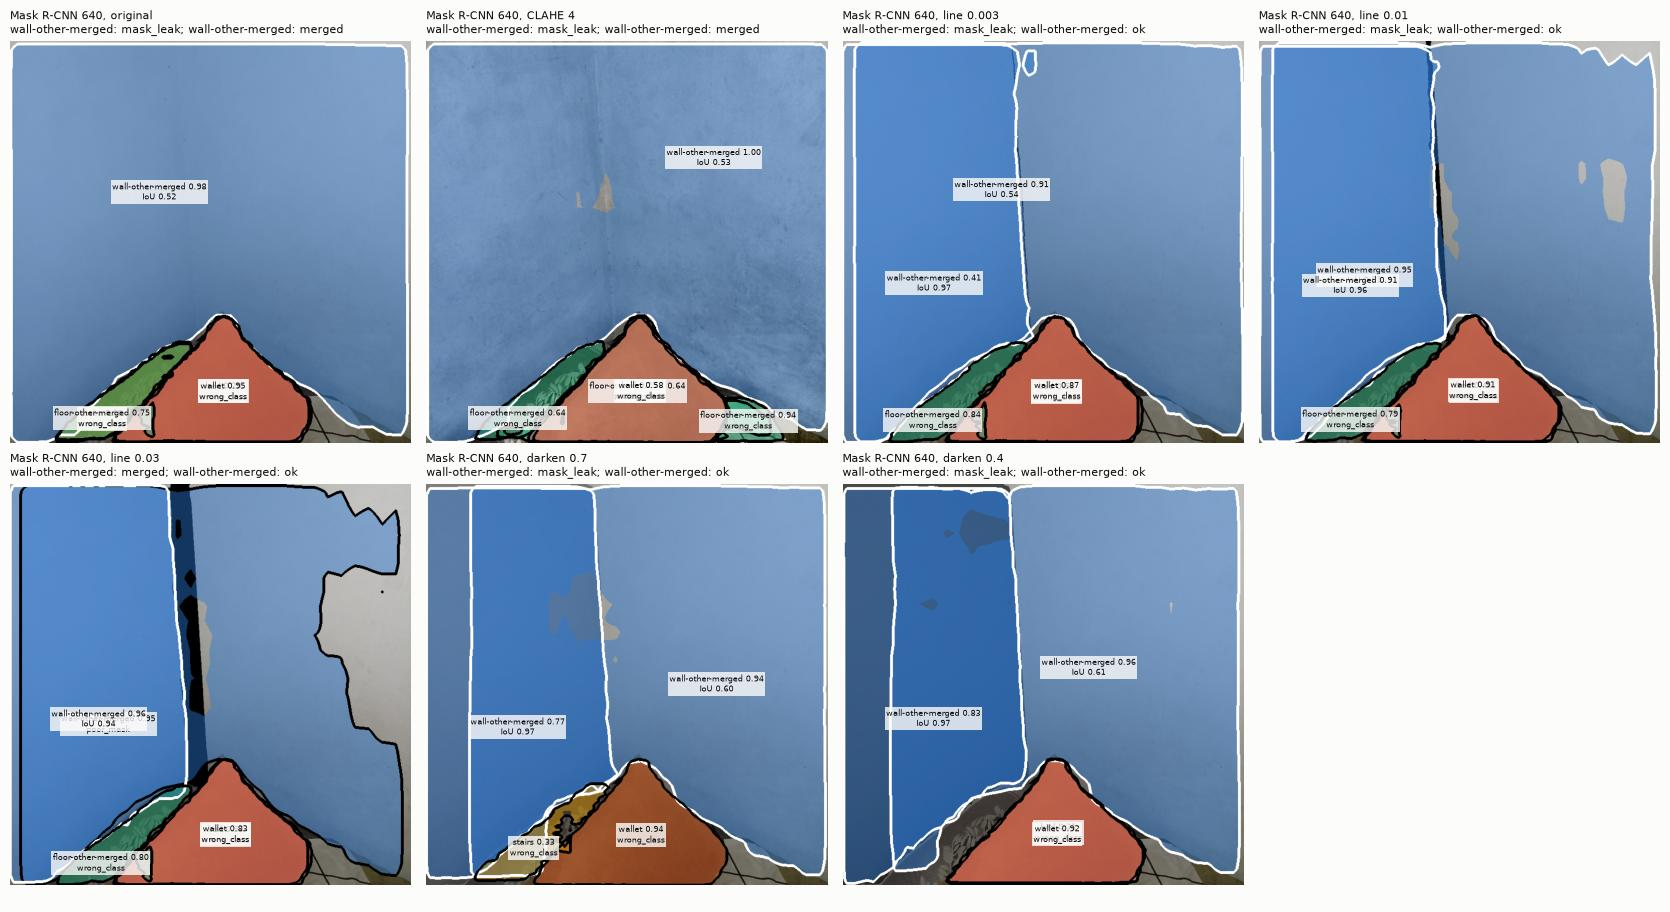

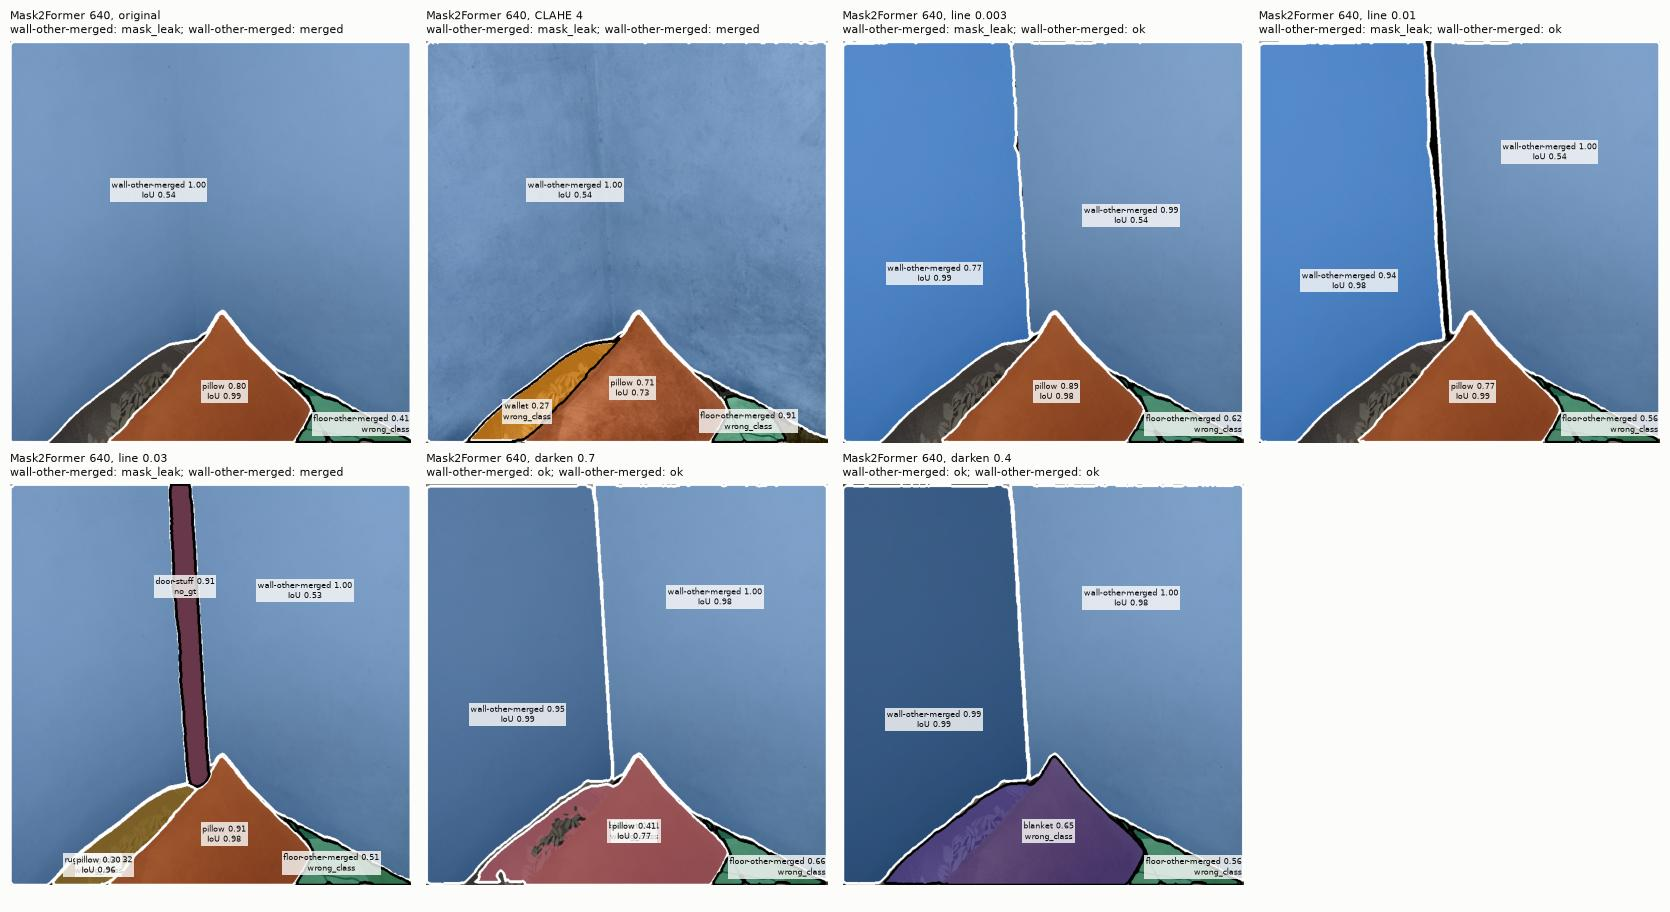

,,model,yolo,maskrcnn,m2f
gt_id,name,variant,,,
93,wall-other-merged,original,mask_leak IoU 0.53 [wall-other-merged 0.85],mask_leak IoU 0.52 [wall-other-merged 0.98],mask_leak IoU 0.54 [wall-other-merged 1.00]
94,wall-other-merged,original,merged,merged,merged
93,wall-other-merged,CLAHE 4,missed,mask_leak IoU 0.53 [wall-other-merged 1.00],mask_leak IoU 0.54 [wall-other-merged 1.00]
94,wall-other-merged,CLAHE 4,missed,merged [wall-other-merged 0.25],merged
93,wall-other-merged,line 0.003,ok IoU 0.97 [wall-other-merged 0.70],mask_leak IoU 0.54 [wall-other-merged 0.91],mask_leak IoU 0.54 [wall-other-merged 0.99]
94,wall-other-merged,line 0.003,ok IoU 0.89 [wall-other-merged 0.49],ok IoU 0.97 [wall-other-merged 0.41],ok IoU 0.99 [wall-other-merged 0.77]
93,wall-other-merged,line 0.01,ok IoU 0.98 [wall-other-merged 0.62],mask_leak IoU 0.51 [wall-other-merged 0.95],mask_leak IoU 0.54 [wall-other-merged 1.00]
94,wall-other-merged,line 0.01,ok IoU 0.94 [wall-other-merged 0.76],ok IoU 0.96 [wall-other-merged 0.91],ok IoU 0.98 [wall-other-merged 0.94]
93,wall-other-merged,line 0.03,ok IoU 0.95 [wall-other-merged 0.90],merged [wall-other-merged 0.20],mask_leak IoU 0.53 [wall-other-merged 1.00]


In [11]:
if "wall_edge" in specs:
    show("wall_edge")
    display(fe.overview(table, "wall_edge"))

## Save the tables

In [12]:
fe.write_tables(table, grid, OUT_DIR)
print("written to", OUT_DIR)

written to results/failures
